# Install dan Import Library

In [ ]:
!pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 620.7/620.7 MB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 109.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 154.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 143.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 224.5/224.5 kB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.5/72.5 kB 7.2 MB/s eta 0:00:00


In [ ]:
!pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.9/250.9 kB 9.8 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_curve
from sklearn.utils import class_weight
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2

/usr/local/lib/python3.12/dist-packages/jax/_src/cloud_tpu_init.py:86: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


# Load Data

In [ ]:
from google.colab import files
upload = files.upload() #upload file data

Saving Data.xlsx to Data.xlsx


In [ ]:
data = pd.read_excel("Data.xlsx")
df = pd.DataFrame(data)
df

,Wilayah,P2,PPK,AHH,RLS,IKK,PKKP,Label
0,Simeulue,0.60,8106,65.775,9.89,108.80,10.08,0
1,Aceh Singkil,0.74,9862,67.935,8.72,94.32,7.41,1
2,Aceh Selatan,0.31,9190,65.020,8.92,98.65,10.44,0
3,Aceh Tenggara,0.35,8876,68.825,10.10,93.43,9.44,0
4,Aceh Timur,0.46,9889,69.230,8.48,95.47,8.71,0
...,...,...,...,...,...,...,...,...
509,Tolikara,0.42,5653,66.560,3.69,288.59,38.64,1
510,Mamberamo Tengah,1.31,4943,64.300,3.70,285.83,29.91,1
511,Yalimo,4.26,5226,66.155,3.55,243.53,14.72,1
512,Yahukimo,0.93,5747,66.575,4.35,169.54,46.36,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 514 entries, 0 to 513
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Wilayah  514 non-null    object 
 1   P2       514 non-null    float64
 2   PPK      514 non-null    int64  
 3   AHH      514 non-null    float64
 4   RLS      514 non-null    float64
 5   IKK      514 non-null    float64
 6   PKKP     514 non-null    float64
 7   Label    514 non-null    int64  
dtypes: float64(5), int64(2), object(1)
memory usage: 32.3+ KB


# Eksplorasi dan Preprocessing

In [ ]:
#Pengecekan Missing Value
df.isnull().sum()

,0
Wilayah,0
P2,0
PPK,0
AHH,0
RLS,0
IKK,0
PKKP,0
Label,0


In [ ]:
#Memisahkan Fitur dan Label
X = df.drop(columns=['Wilayah','Label'])
y = df['Label']

In [ ]:
#Pengecekan Outlier
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
outliers = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR)))

print("Jumlah Outlier Masing-Masing Variabel:")
print(outliers.sum())

Jumlah Outlier Masing-Masing Variabel:
P2      52
PPK     16
AHH      9
RLS     16
IKK     32
PKKP    46
dtype: int64


In [ ]:
#Statistik Deskriptif Fitur
X.describe()

,P2,PPK,AHH,RLS,IKK,PKKP
count,514.000000,514.000000,514.000000,514.000000,514.000000,514.000000
mean,0.443327,11435.441634,70.474825,8.740856,105.521907,11.079689
std,0.552465,2820.506410,3.417311,1.613603,29.900488,8.730862
min,0.010000,4597.000000,55.905000,1.920000,77.030000,0.870000
25%,0.160000,9648.000000,68.315000,7.820000,93.845000,6.197500
50%,0.270000,11305.000000,70.655000,8.615000,99.655000,8.690000
75%,0.490000,12896.750000,72.822500,9.610000,106.620000,12.335000
max,5.350000,25573.000000,78.375000,13.100000,379.810000,57.910000


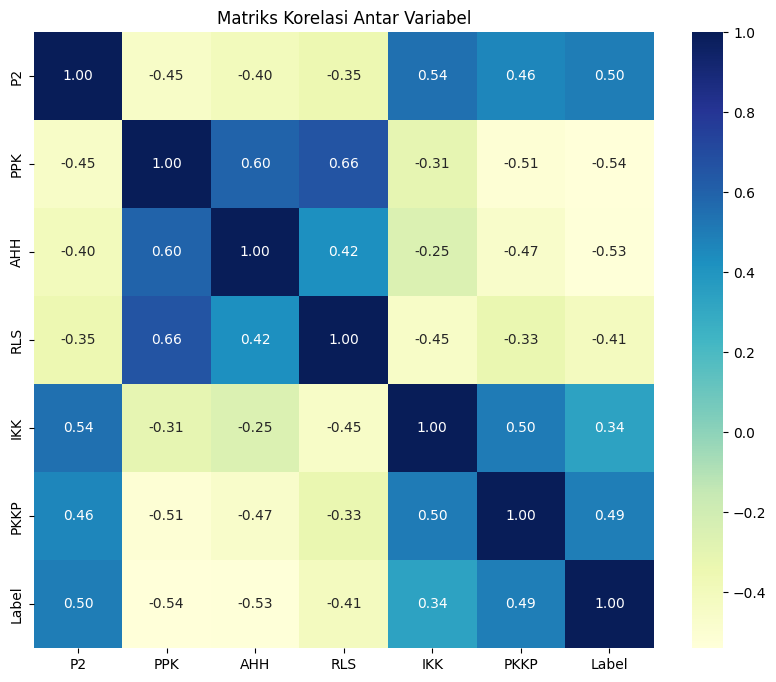

In [ ]:
#Plot Korelasi Antar Variabel
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Matriks Korelasi Antar Variabel")
plt.show()

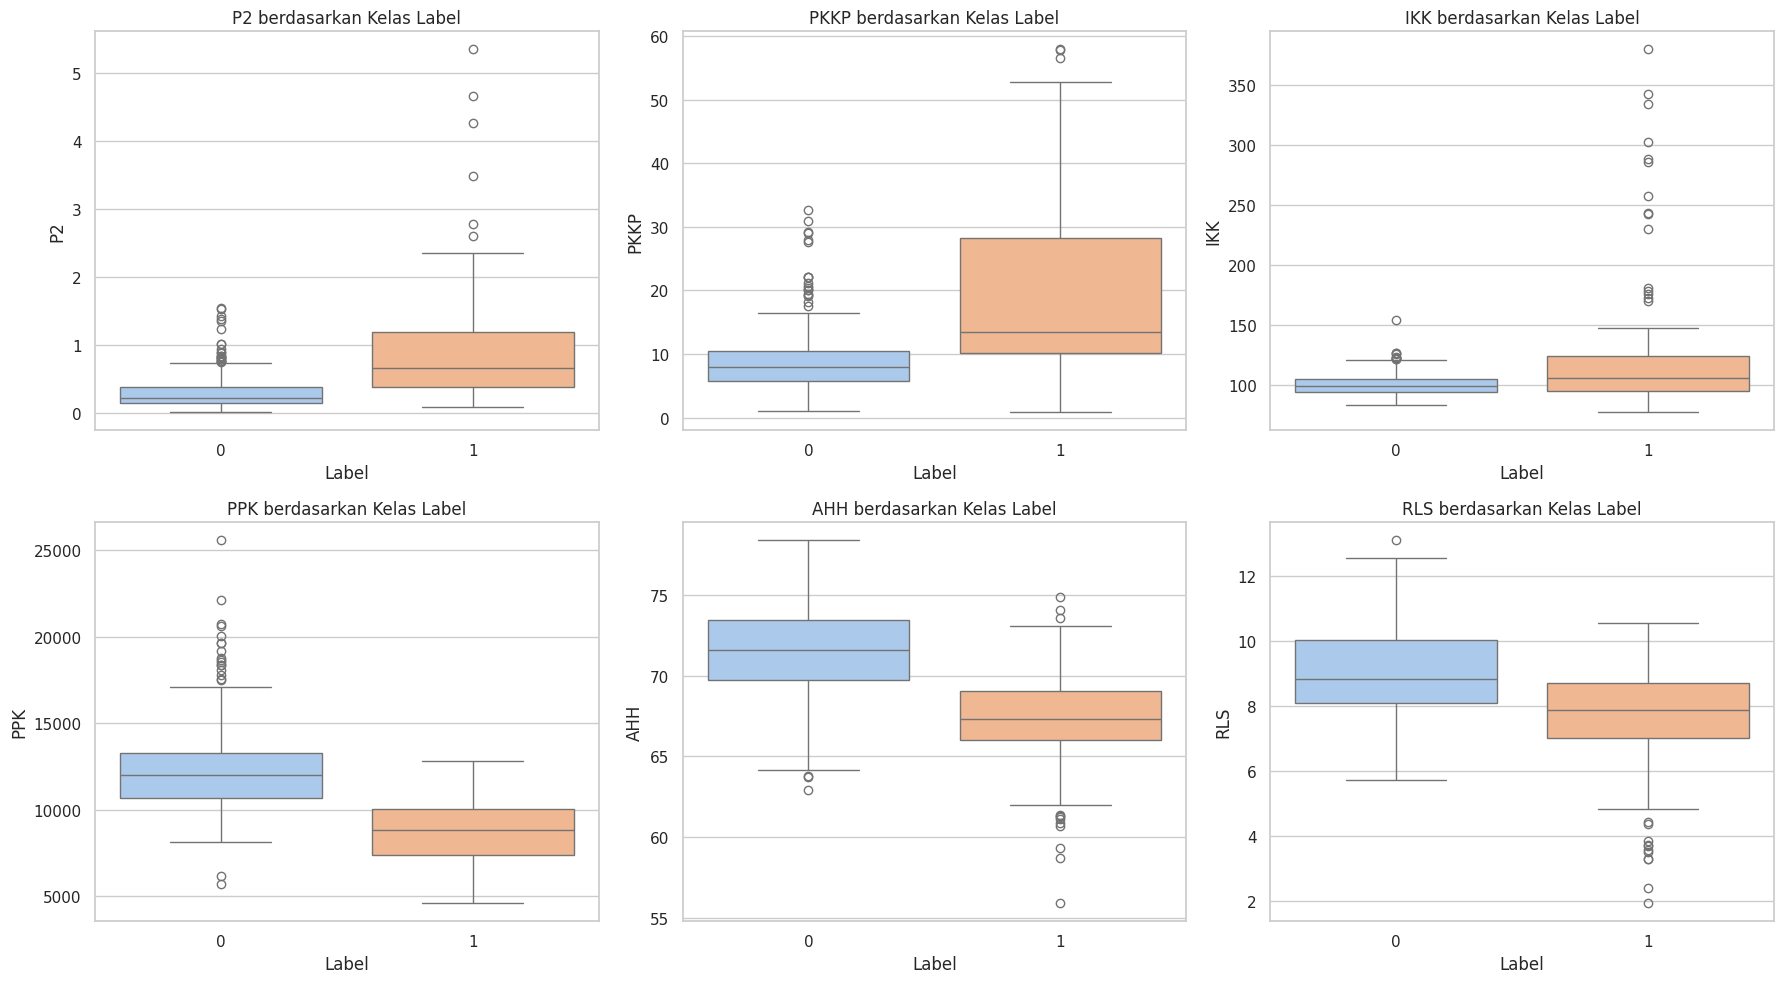

In [ ]:
#Boxplot Fitur Berdasarkan Kategori Label
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set(style="whitegrid")

# Misal X berisi 6 kolom
cols = ['P2','PKKP','IKK','PPK','AHH','RLS']

plt.figure(figsize=(18, 10))  # ukuran besar agar tetap jelas

for i, col in enumerate(cols, 1):
    plt.subplot(2, 3, i)  # 2 baris 3 kolom
    sns.boxplot(x='Label', y=col, data=df, palette='pastel')
    plt.title(f'{col} berdasarkan Kelas Label')
    plt.xlabel('Label')
    plt.ylabel(col)

plt.tight_layout()
plt.show()


In [ ]:
#Distribusi Frekuensi Label
print("Jumlah daerah tertinggal (label = 1):", (df['Label'] == 1).sum())
print("Jumlah daerah tidak tertinggal (label = 0):", (df['Label'] == 0).sum())

Jumlah daerah tertinggal (label = 1): 122
Jumlah daerah tidak tertinggal (label = 0): 392


In [ ]:
#Penanganan Ketidakseimbangan Kelas untuk Model ANN
weights = class_weight.compute_class_weight(
    'balanced',
    classes=np.unique(df['Label']),
    y=df['Label']
)

class_weights = dict(enumerate(weights))
print(class_weights)

{0: np.float64(0.6556122448979592), 1: np.float64(2.1065573770491803)}


In [ ]:
#Transformasi Data
scaler = RobustScaler()
X_scaled = scaler.fit_transform(X)
X_scaled

array([[ 1.        , -0.98468642, -1.08264004,  0.7122905 ,  0.71585127,
         0.22647658],
       [ 1.42424242, -0.44417083, -0.60343871,  0.05865922, -0.41761252,
        -0.20855397],
       [ 0.12121212, -0.65101962, -1.25013866,  0.17039106, -0.07866928,
         0.28513238],
       ...,
       [12.09090909, -1.87118122, -0.99833611, -2.82960894, 11.26223092,
         0.98248473],
       [ 2.        , -1.71081185, -0.90515807, -2.38268156,  5.4704501 ,
         6.13767821],
       [ 4.72727273, -1.57260485, -1.23017194, -2.85195531, 15.88062622,
         1.49898167]])

In [ ]:
#Split Data
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y,
                                                    test_size = 0.2,
                                                    random_state = 22020,
                                                    stratify = y)

# ANN

In [ ]:
#Membangun Model
model = Sequential([
                Input(shape=(X_train.shape[1],)),

                Dense(12, activation='relu',kernel_regularizer=l2(0.0001)),
                BatchNormalization(),
                Dropout(0.2),

                Dense(6, activation='relu',kernel_regularizer=l2(0.0001)),
                BatchNormalization(),
                Dropout(0.1),

                Dense(1, activation='sigmoid')
                ])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12)             │            84 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12)             │            48 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │            78 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 6)              │            24 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             7 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241 (964.00 B)

 Trainable params: 205 (820.00 B)

 Non-trainable params: 36 (144.00 B)

In [ ]:
#Training Model
history = model.fit(X_train, y_train,
          validation_split=0.2,
          epochs=50,
          batch_size=16,
          class_weight=class_weights,
          verbose=1)

Epoch 1/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5586 - loss: 0.7708 - val_accuracy: 0.4217 - val_loss: 0.7302
Epoch 2/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5819 - loss: 0.7518 - val_accuracy: 0.6506 - val_loss: 0.6990
Epoch 3/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6661 - loss: 0.6644 - val_accuracy: 0.7470 - val_loss: 0.6682
Epoch 4/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6030 - loss: 0.6940 - val_accuracy: 0.7590 - val_loss: 0.6396
Epoch 5/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6841 - loss: 0.7111 - val_accuracy: 0.7831 - val_loss: 0.6198
Epoch 6/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7239 - loss: 0.6294 - val_accuracy: 0.8072 - val_loss: 0.6015
Epoch 7/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7512 - loss: 0.5768 - val_accuracy: 0.8072 - val_loss: 0.5828
Epoch 8/50
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7611 - loss: 0.5475 - val_accuracy: 0.8193 - val_loss

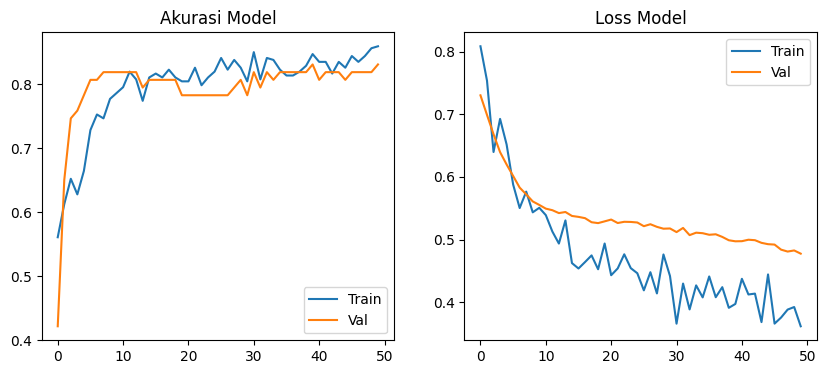

In [ ]:
#Plot Akurasi dan Loss Model
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Val')
plt.title('Akurasi Model')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Val')
plt.title('Loss Model')
plt.legend()
plt.show()

In [ ]:
#Mencari Threshold Optimal (Statistik Youden's J)
y_prob = model.predict(X_test)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
J = tpr - fpr
best_threshold = thresholds[J.argmax()]
print("Threshold optimal:", best_threshold)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
Threshold optimal: 0.76378196


In [ ]:
#Evaluasi Model menggunakan F1-Score
y_pred = (model.predict(X_test) > best_threshold).astype(int)
print(classification_report(y_test, y_pred))
print("Akurasi:", accuracy_score(y_test, y_pred))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
              precision    recall  f1-score   support

           0       0.94      0.95      0.94        79
           1       0.83      0.79      0.81        24

    accuracy                           0.91       103
   macro avg       0.88      0.87      0.88       103
weighted avg       0.91      0.91      0.91       103

Akurasi: 0.912621359223301


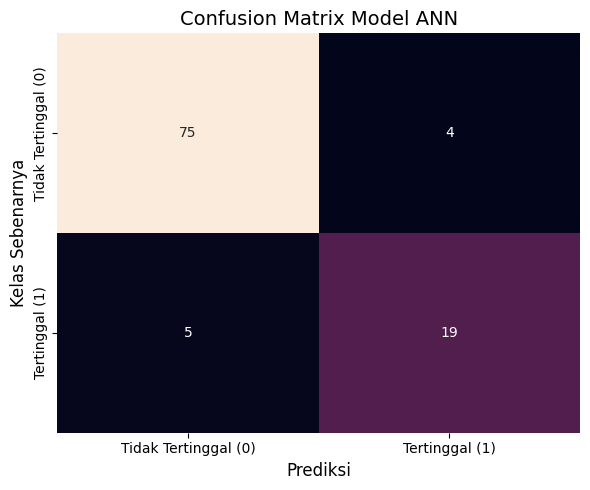

In [ ]:
#Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cbar=False,
            xticklabels=['Tidak Tertinggal (0)', 'Tertinggal (1)'],
            yticklabels=['Tidak Tertinggal (0)', 'Tertinggal (1)'])

plt.title('Confusion Matrix Model ANN', fontsize=14)
plt.xlabel('Prediksi', fontsize=12)
plt.ylabel('Kelas Sebenarnya', fontsize=12)
plt.tight_layout()
plt.show()
